In [ ]:
!pip install --upgrade git+https://github.com/keras-team/keras-cv -q # this is moving to kerashub soon
!pip install mlflow mapillary -q
!pip install --upgrade protobuf

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import json
import tempfile

import requests
from tqdm.auto import tqdm
import xml.etree.ElementTree as ET
from bs4 import BeautifulSoup
from io import BytesIO # create file-like object from bytes
from PIL import Image, UnidentifiedImageError # image data
import psutil

import tensorflow as tf
from tensorflow import keras
from keras import mixed_precision
from keras.callbacks import TensorBoard
from keras.models import load_model
import keras_cv
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

import mapillary as mly
import logging

In [ ]:
IMAGE_SIZE = 1024
BATCH_SIZE = 16
N_IMAGES = 1434 #1657

In [ ]:
def silence_mapillary(level=logging.WARNING, to_file=None):
    # The SDK uses these logger names
    names = ["mapillary", "mapillary.utils", "mapillary.utils.client"]

    # Optionally route to a file instead of stdout
    handler = logging.FileHandler(to_file) if to_file else logging.StreamHandler()
    handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(name)s | %(message)s"))

    for name in names:
        lg = logging.getLogger(name)
        # remove any existing handlers that Jupyter/root added
        lg.handlers.clear()
        # prevent bubbling to root (which causes the "INFO:mapillary..." duplicates)
        lg.propagate = False
        lg.setLevel(level)
        lg.addHandler(handler)

# Example usages:
# 1) Silence Mapillary INFO entirely (show only warnings+):
silence_mapillary(level=logging.WARNING)

def id_to_url_tf(img_id_tf: tf.Tensor, resolution=2048) -> tf.Tensor:
    def _py(id_in):
        img_id = id_in.numpy().decode("utf-8")
        try:
            url = mly.interface.image_thumbnail(image_id=img_id, resolution=resolution)
            return url.encode("utf-8")
        except Exception:
            return b""
    return tf.py_function(_py, [img_id_tf], Tout=tf.string)

def url_to_uint8_tf(url_tf: tf.Tensor) -> tf.Tensor:
    def _py(url_bytes):
        url = url_bytes.numpy().decode("utf-8")
        if not url:
            return np.zeros((8,8,3), np.uint8)
        with requests.get(url, stream=True, timeout=30) as r:
            #r.raise_for_status()
            buf = BytesIO(r.content)
        img = Image.open(buf).convert("RGB")
        return np.array(img, dtype=np.uint8)
    img = tf.py_function(_py, [url_tf], Tout=tf.uint8)
    img.set_shape([None, None, 3])
    return img


def load_dataset(image_id, classes, bbox, normalize = False):
    # Read Image
    url_tf = id_to_url_tf(image_id)            # tf.string
    image = url_to_uint8_tf(url_tf)
    image.set_shape([None, None, 3])
    classes = tf.cast(classes, tf.int32)
    boxes    = tf.cast(bbox,   tf.float32)     # stays ragged if input is ragged

    # inline normalize: (only for dense)
    # if normalize:
    #   boxes = _normalize_boxes_xyxy(boxes, image)

    bounding_boxes = {"classes": classes, "boxes": boxes}
    return {"images": image, "bounding_boxes": bounding_boxes}


def dict_to_tuple(sample):
  images = sample["images"]
  bbox   = sample["bounding_boxes"]
  dense = keras_cv.bounding_box.to_dense(
      {"boxes": bbox["boxes"], "classes": bbox["classes"]}  # only numeric fields
  )
  return images, dense




In [ ]:
OUTPUT_PATH = "/content/drive/MyDrive/Flags/"

# mount drive
from google.colab import drive
drive.mount('/content/drive')

# os.environ["MLY_KEY"] = MLY_KEY
mly.interface.set_access_token(MLY_KEY)

# load my model trained in 02_
yolo = load_model(OUTPUT_PATH + f"trained/trained_yolo_model_{N_IMAGES}-1024.keras")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
with open(OUTPUT_PATH + f"inputs/validation_ds_inputs_{N_IMAGES}.pkl", "rb") as f:
    val_data_dict = pickle.load(f)
val_image_paths = tf.constant(val_data_dict["image_paths"], dtype=tf.string)
val_classes     = val_data_dict["classes"]  # already RaggedTensor
val_boxes       = val_data_dict["boxes"]    # already RaggedTensor

# create dataset from slices
val_data = tf.data.Dataset.from_tensor_slices((val_image_paths, val_classes, val_boxes))

In [ ]:
val_resizer = keras_cv.layers.Resizing(
    height=IMAGE_SIZE,
    width=IMAGE_SIZE,
    pad_to_aspect_ratio=True,
    bounding_box_format="xyxy",
)
val_ds = (
    val_data
    .map(
      lambda iid, cls, bx: load_dataset(
          image_id=iid,
          classes=cls,
          bbox=bx,
          normalize = False
      ),
      num_parallel_calls=tf.data.AUTOTUNE
    )
    #.shuffle(buffer_size=1000)
    .map(val_resizer, num_parallel_calls=tf.data.AUTOTUNE)
    .ragged_batch(batch_size=BATCH_SIZE)
    .map(dict_to_tuple, num_parallel_calls=tf.data.AUTOTUNE)  # → (images, dict) dense
    .prefetch(tf.data.AUTOTUNE)
)


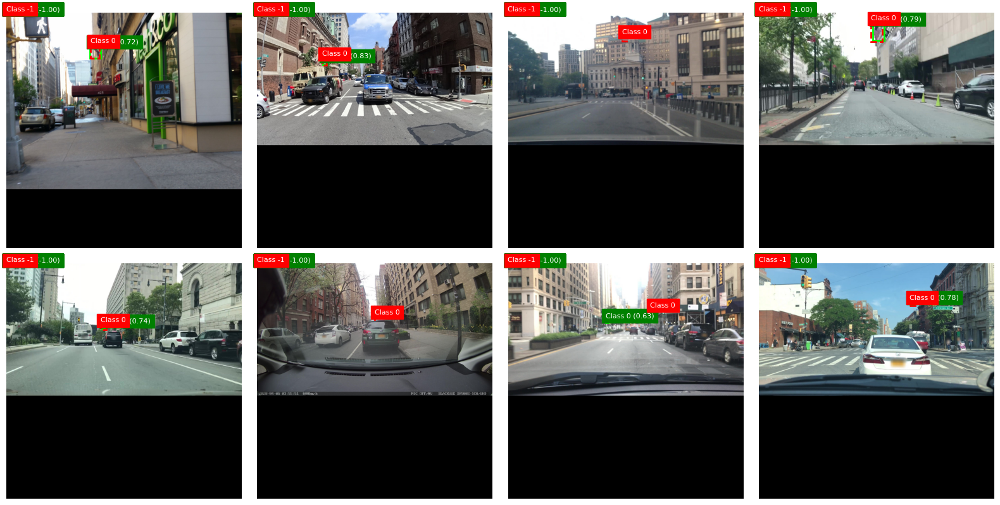

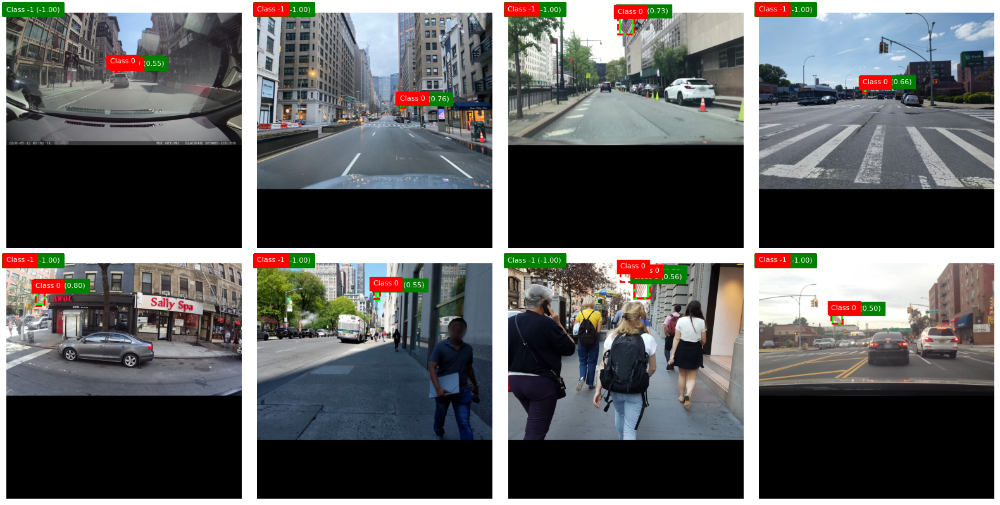

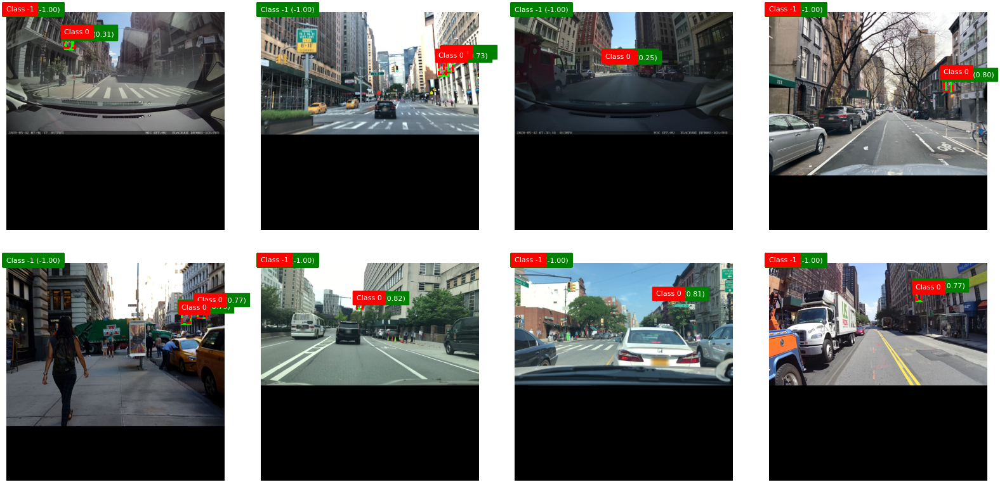

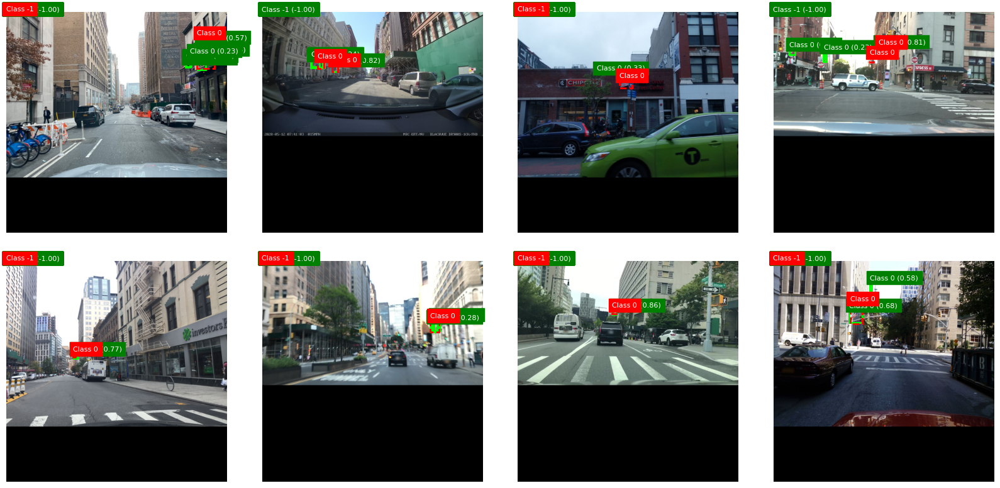

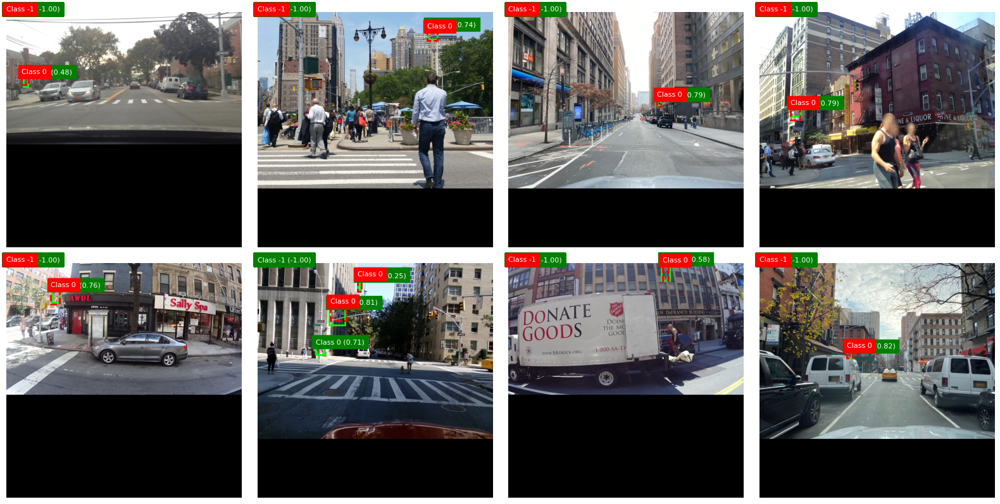

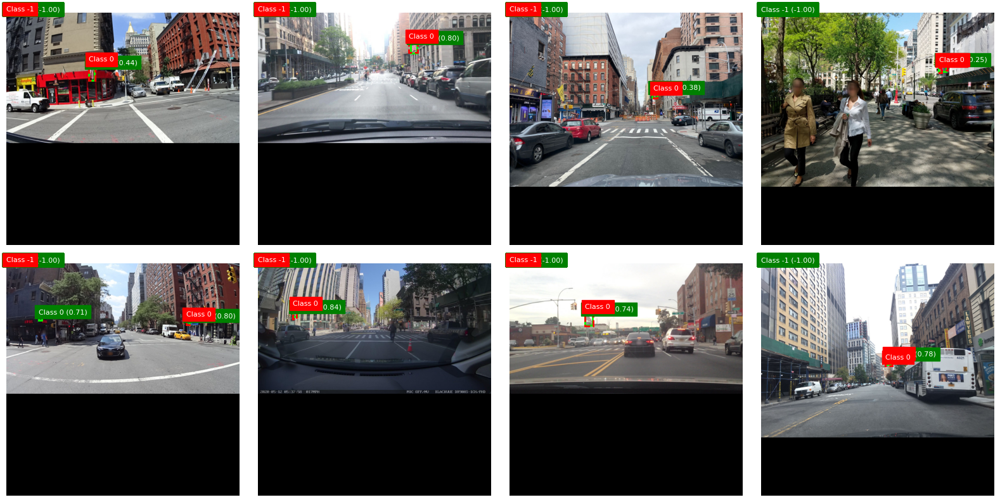

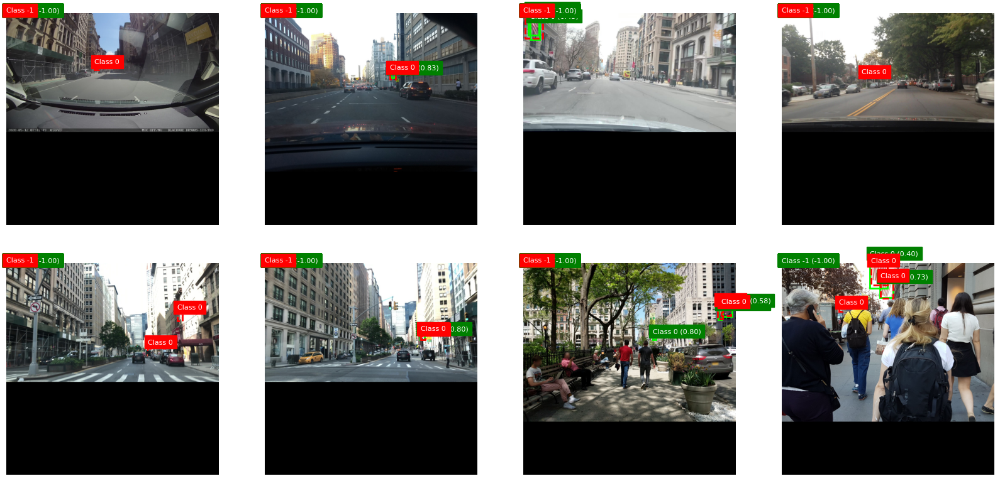

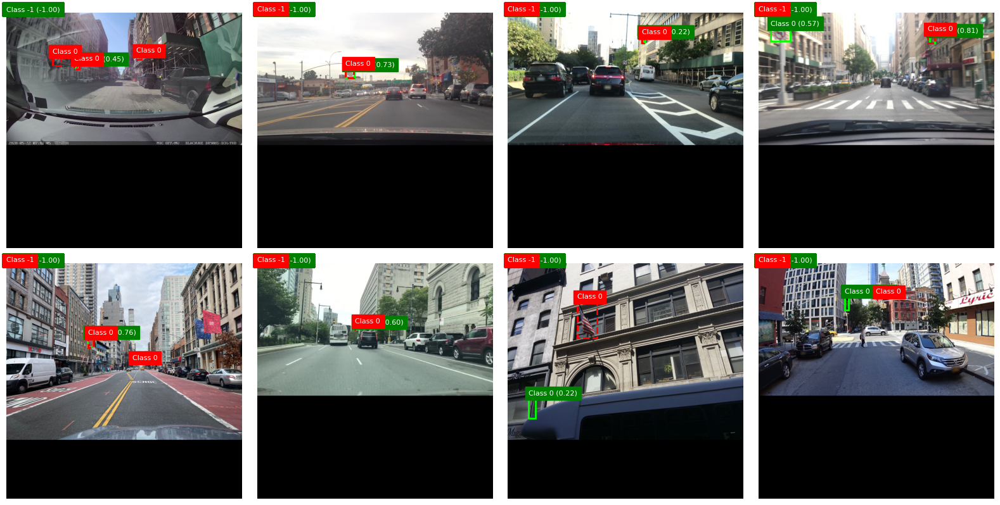

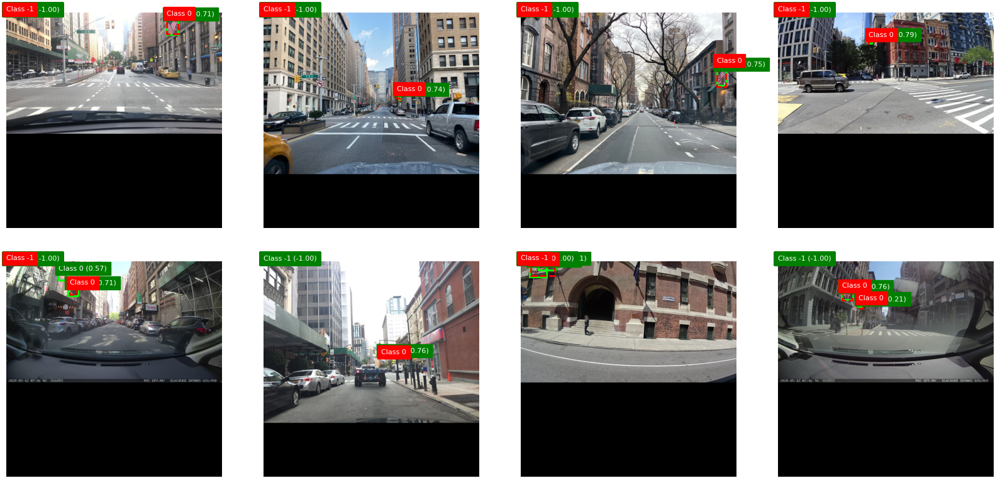

In [ ]:
for images, y_true in val_ds.take(10):
  # returns dense stensors of (batch size, grid size x grid size, num_anchors, 5+ num_classes)
  # 5 b/c: x = center x coord, y = center y -coord, w, h, objectness, class probs  for each class

  # Plot up to 16 predictions
  raw_predictions = yolo(images, training=False)
  decoded_preds = yolo.decode_predictions(raw_predictions, images)
  plt.figure(figsize=(16, 16))
  for i in range(min(8, len(images))):
      img = images[i].numpy().astype("uint8")

      # predicted
      pred_boxes = decoded_preds["boxes"][i].numpy()
      pred_classes = decoded_preds["classes"][i].numpy()
      pred_confs = decoded_preds["confidence"][i].numpy()

      # actual
      true_boxes = y_true["boxes"][i].numpy()
      true_classes = y_true["classes"][i].numpy()

      ax = plt.subplot(4, 4, i + 1)
      ax.imshow(img)

      # predicted boxes
      for box, cls, conf in zip(pred_boxes, pred_classes, pred_confs):
          x1, y1, x2, y2 = box
          rect = patches.Rectangle(
              (x1, y1), x2 - x1, y2 - y1,
              linewidth=2, edgecolor='lime', facecolor='none'
          )
          ax.add_patch(rect)
          ax.text(x1, y1 - 5, f"Class {int(cls)} ({conf:.2f})", color='white',
                  fontsize=8, backgroundcolor='green')

      # actual boxes
      for box, cls in zip(true_boxes, true_classes):
          x1, y1, x2, y2 = box
          rect = patches.Rectangle(
              (x1, y1), x2 - x1, y2 - y1,
              linewidth=2, edgecolor='red', facecolor='none', linestyle='dashed'
          )
          ax.add_patch(rect)
          ax.text(x1, y1 - 5, f"Class {int(cls)}", color='white',
                  fontsize=8, backgroundcolor='red')

      ax.axis('off')

  plt.tight_layout()
  plt.show()

In [ ]:
# gathering and formatting the model predictions
all_preds = []
image_id = 0

# predictions
for images, _ in val_ds:
  raw_predictions = yolo(images, training=False)
  predictions = yolo.decode_predictions(raw_predictions, images)

  for i in range(len(images)):
    boxes = predictions['boxes'][i].numpy() # why is numpy necessary
    scores = predictions['confidence'][i].numpy()
    classes = predictions['classes'][i].numpy()

    for box, cls, score in zip(boxes, classes, scores):
        if score < 0.05: continue # threshold
        x1, y1, x2, y2 = box
        all_preds.append({
            "image_id": image_id,
            "category_id": int(cls),
            "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
            "score": float(score),
        })
    image_id += 1

In [ ]:
# ground truth
all_gts = []
image_id = 0

for _, y_true in val_ds:
    for i in range(len(y_true["boxes"])):
        boxes = y_true["boxes"][i].numpy()
        classes = y_true["classes"][i].numpy()
        for box, cls in zip(boxes, classes):
            if cls == -1: continue
            x1, y1, x2, y2 = box
            all_gts.append({
                "image_id": image_id,
                "category_id": int(cls),
                "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                "iscrowd": 0,
            })
        image_id += 1

In [ ]:
# Save to temp file
# Create categories and images lists
categories = [{"id": i, "name": str(i)} for i in set(gt["category_id"] for gt in all_gts)]

# Step 2: Unique image IDs (ensure same total count as used in val_ds.take(N))
image_ids = sorted(set(gt["image_id"] for gt in all_gts))
images = [{"id": i} for i in image_ids]

# Step 3: Add unique annotation IDs
for i, ann in enumerate(all_gts):
    ann["id"] = i
    x, y, w, h = ann["bbox"]
    ann["area"] = float(w * h)
    ann["iscrowd"] = ann.get("iscrowd", 0)  # make sure this is present

# Step 4: Final COCO ground truth dict
gt_dict = {
        "info": {
        "description": "Validation dataset",
        "version": "1.0",
        "year": 2025,
    },
    "images": images,
    "annotations": all_gts,
    "categories": categories,
}
gt_file = tempfile.NamedTemporaryFile(delete=False, suffix=".json")
json.dump(gt_dict, open(gt_file.name, 'w'))
# save preds too
pred_file = tempfile.NamedTemporaryFile(delete=False, suffix=".json")
json.dump(all_preds, open(pred_file.name, 'w'))

In [ ]:
coco_gt = COCO(gt_file.name)
coco_dt = coco_gt.loadRes(pred_file.name)
coco_eval = COCOeval(coco_gt, coco_dt, iouType='bbox')
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.04s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.176
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.501
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.072
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.118
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.273
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.234
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.222
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.272
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets

In [ ]:
coco_eval.params.iouThrs = [0.2, 0.3, 0.4, 0.5, 0.6]
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()

# precision array: [IoU, recall, class, area range, maxDet]
prec = coco_eval.eval['precision']  # shape: [T, R, K, A, M]
recall = coco_eval.eval['recall']  # shape: [T, R, K, A]

iou_thrs = coco_eval.params.iouThrs
rec_thrs = coco_eval.params.recThrs
cat_ids = coco_eval.params.catIds
area_ind = 0  # 0 = 'all'
max_det_ind = 2  # 2 = maxDets=100

for i, iou in enumerate(iou_thrs):
    ap = np.mean(prec[i, :, :, area_ind, max_det_ind])
    ar = np.mean(recall[i, :, area_ind, max_det_ind])
    print(f"AP @ IoU={iou:.2f}: {ap:.3f}")

    r = recall[i, :, area_ind, max_det_ind]  # recall at this IoU, all classes
    valid = r[r > -1]  # COCO uses -1 for missing data
    if valid.size > 0:
        ar = np.mean(valid)
        print(f"AR @ IoU={iou:.2f}: {ar:.3f}")
    else:
        print(f"AR @ IoU={iou:.2f}: N/A")
    print("---")

Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.04s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.20:0.60 | area=   all | maxDets=100 ] = 0.586
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.20:0.60 | area= small | maxDets=100 ] = 0.481
 Average Precision  (AP) @[ IoU=0.20:0.60 | area=medium | maxDets=100 ] = 0.738
 Average Precision  (AP) @[ IoU=0.20:0.60 | area= large | maxDets=100 ] = 0.653
 Average Recall     (AR) @[ IoU=0.20:0.60 | area=   all | maxDets=  1 ] = 0.564
 Average Recall     (AR) @[ IoU=0.20:0.60 | area=   all | maxDets= 10 ] = 0.678
 Average Recall     (AR) @[ IoU=0.20:0.60 | area=   all | maxDets=100 ] = 0.678
 Average Recall     (AR) @[ IoU=0.20:0.60 | area= small | maxDets=100 ] = 0.571
 Average Recall     (AR) @[ IoU=0.20:0.60 | area=medium | maxDets=1